In [1]:
import cv2 as cv

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
def getPath(name: str) -> str:
    import os
    from dotenv import load_dotenv
    load_dotenv()

    # 1. Сначала берем значение пути ИЗ файла .env по ключу (например, "1_PNG")
    env_path = os.getenv(name)
    
    if env_path is None:
        raise ValueError(f"Ключ '{name}' не найден в .env. Проверьте синтаксис!")
        
    # 2. И только потом раскрываем тильду ~ в полноценный путь
    return os.path.expanduser(env_path)

In [5]:
try:
    path = getPath("3_PNG")
    image = cv.imread(path)
    
    if image is None:
        print(f"Ошибка чтения: OpenCV не смог открыть файл по пути {path}")
    else:
        cv.imshow("Window Name", image)
        cv.waitKey(0)
        cv.destroyAllWindows()
except Exception as e:
    print(e)

QFontDatabase: Cannot find font directory /home/er1ta1n/kubsu/course_4/multimedia/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/er1ta1n/kubsu/course_4/multimedia/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/er1ta1n/kubsu/course_4/multimedia/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/er1ta1n/kubsu/course_4/multimedia/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or sw

In [6]:
image.shape

(720, 1280, 3)

In [7]:
image.dtype

dtype('uint8')

In [8]:
cv.imwrite( f"{getPath('RESULT_DIR')}/result.png", image)   #Если приблизить к светофору, то на png и jpg будет разные цвета некоторых пикселей.
cv.imwrite( f"{getPath('RESULT_DIR')}/result.jpg", image)   

True

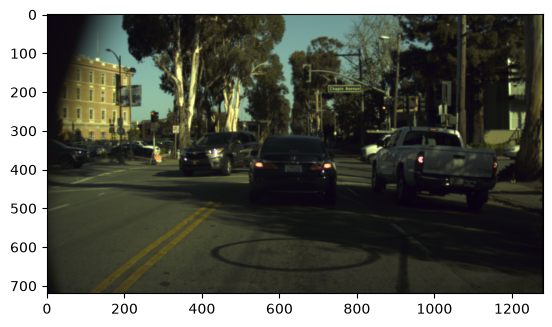

In [9]:
rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)
plt.imshow(rgb)
plt.show()

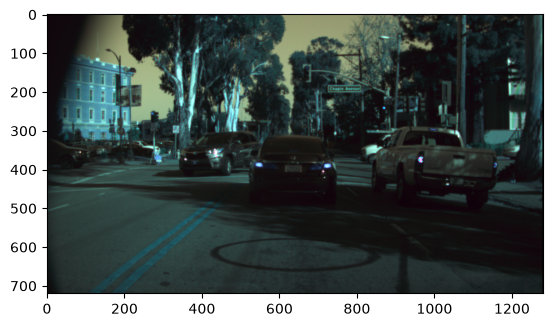

In [10]:
rgb = cv.cvtColor(rgb, cv.COLOR_BGR2RGB)
plt.imshow(rgb)
plt.show()

In [11]:
x, y, width, height = cv.selectROI(image)
cv.destroyAllWindows()
if width == 0 or height == 0:
    raise ValueError("Выделите область со светофором")
roi = image[y:y + height, x:x + width]

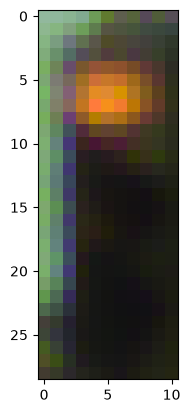

In [12]:
rgb = cv.cvtColor(roi, cv.COLOR_BGR2RGB)
plt.imshow(rgb)
plt.show()

In [13]:
# Перевод области с светофором в HSV
hsv = cv.cvtColor(roi, cv.COLOR_BGR2HSV)
value = hsv[:,:, 2]

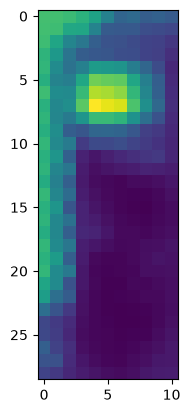

In [14]:
plt.imshow(value)
plt.show()

In [15]:
# Маски для цветов
green = cv.inRange(hsv, (40, 80, 0), (90, 255, 255))
yellow = cv.inRange(hsv, (15, 80, 0), (35, 255, 255))
red_down = cv.inRange(hsv, (0, 80, 0), (10, 255, 255))
red_up = cv.inRange(hsv, (170, 80, 0), (170, 255, 255))

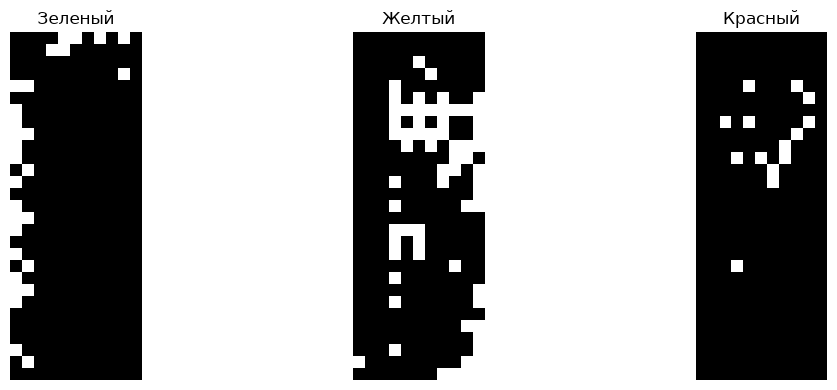

In [16]:

red = cv.bitwise_or(red_down, red_up)

masks = [green, yellow, red]
titles = ["Зеленый", "Желтый", "Красный"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, mask, title in zip(axes, masks, titles):
    ax.imshow(mask, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")   # убрать оси и рамку

plt.tight_layout()
plt.show()

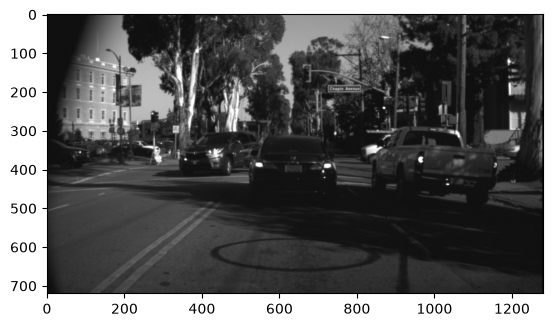

In [17]:
hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)
value = hsv[:,:, 2]
plt.imshow(value, cmap="gray", vmin=0, vmax=255)
plt.show()


In [18]:
# Маски для цветов
green = cv.inRange(hsv, (40, 80, 0), (90, 255, 255))
yellow = cv.inRange(hsv, (15, 80, 0), (35, 255, 255))
red_down = cv.inRange(hsv, (0, 80, 0), (10, 255, 255))
red_up = cv.inRange(hsv, (170, 80, 0), (170, 255, 255))

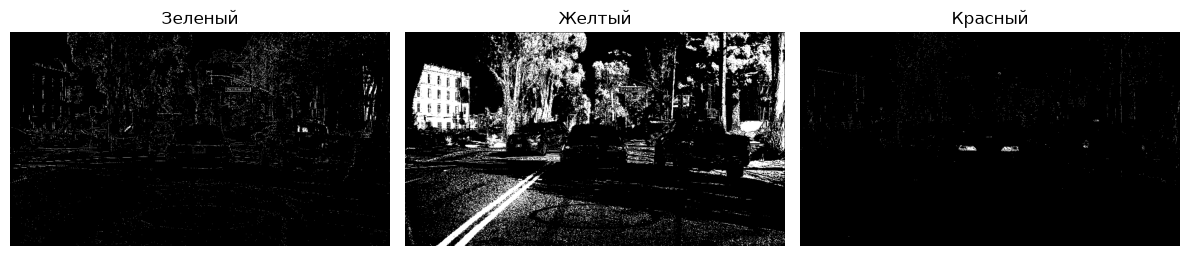

In [19]:
red = cv.bitwise_or(red_down, red_up)

masks = [green, yellow, red]
titles = ["Зеленый", "Желтый", "Красный"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, mask, title in zip(axes, masks, titles):
    ax.imshow(mask, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")   # убрать оси и рамку

plt.tight_layout()
plt.show()

In [20]:
# Гистограмма для области со светофором

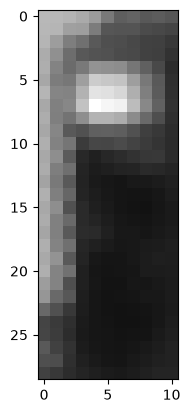

In [21]:
hsv = cv.cvtColor(roi, cv.COLOR_BGR2HSV)
value_Stoplight = hsv[:,:, 2]
plt.imshow(value_Stoplight, cmap="gray", vmin=0, vmax=255)
plt.show()

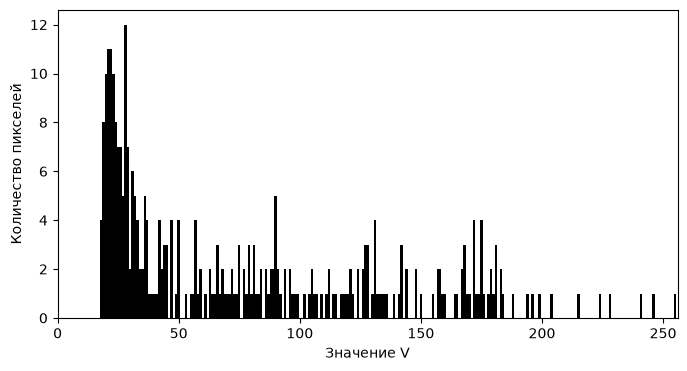

In [22]:
hist = cv.calcHist([value_Stoplight], [0], None, [256], [0, 256])

plt.figure(figsize=(8, 4))
plt.bar(np.arange(256), hist.ravel(), width=1, color="black")
plt.xlim(0, 256)
plt.xlabel("Значение V")
plt.ylabel("Количество пикселей")
plt.show()

In [23]:
# Гистограмма для всего изображения

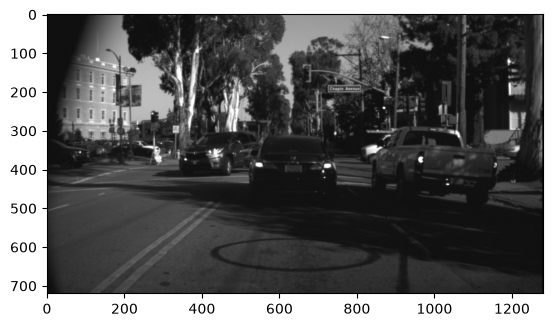

In [24]:
hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)
value_allImage = hsv[:,:, 2]
plt.imshow(value_allImage, cmap="gray", vmin=0, vmax=255)
plt.show()

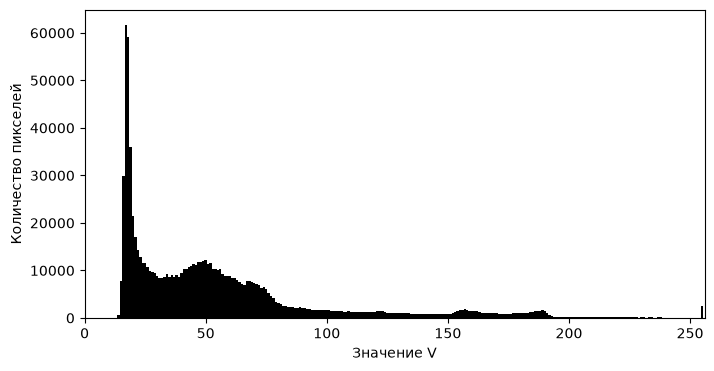

In [25]:
hist = cv.calcHist([value_allImage], [0], None, [256], [0, 256])

plt.figure(figsize=(8, 4))
plt.bar(np.arange(256), hist.ravel(), width=1, color="black")
plt.xlim(0, 256)
plt.xlabel("Значение V")
plt.ylabel("Количество пикселей")
plt.show()

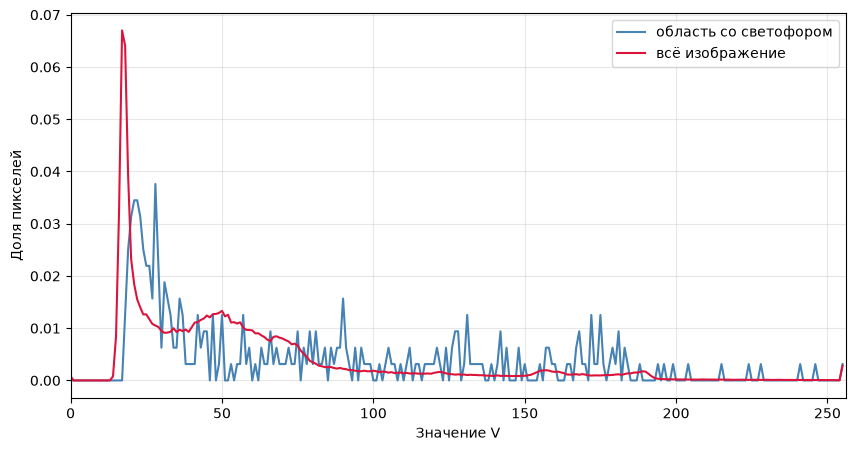

In [26]:
h1, _ = np.histogram(value_Stoplight, bins=256, range=(0, 256))
h2, _ = np.histogram(value_allImage, bins=256, range=(0, 256))

h1 = h1 / h1.sum()
h2 = h2 / h2.sum()

plt.figure(figsize=(10, 5))
plt.plot(h1, color="steelblue", label="область со светофором")
plt.plot(h2, color="crimson",   label="всё изображение")
plt.xlim(0, 256)
plt.xlabel("Значение V")
plt.ylabel("Доля пикселей")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [27]:
# Сравним ручной порог и метод Оцу

In [28]:
# Ручной порог

In [29]:
T = 60
_, manual = cv.threshold(value_Stoplight, T, 255, cv.THRESH_BINARY)


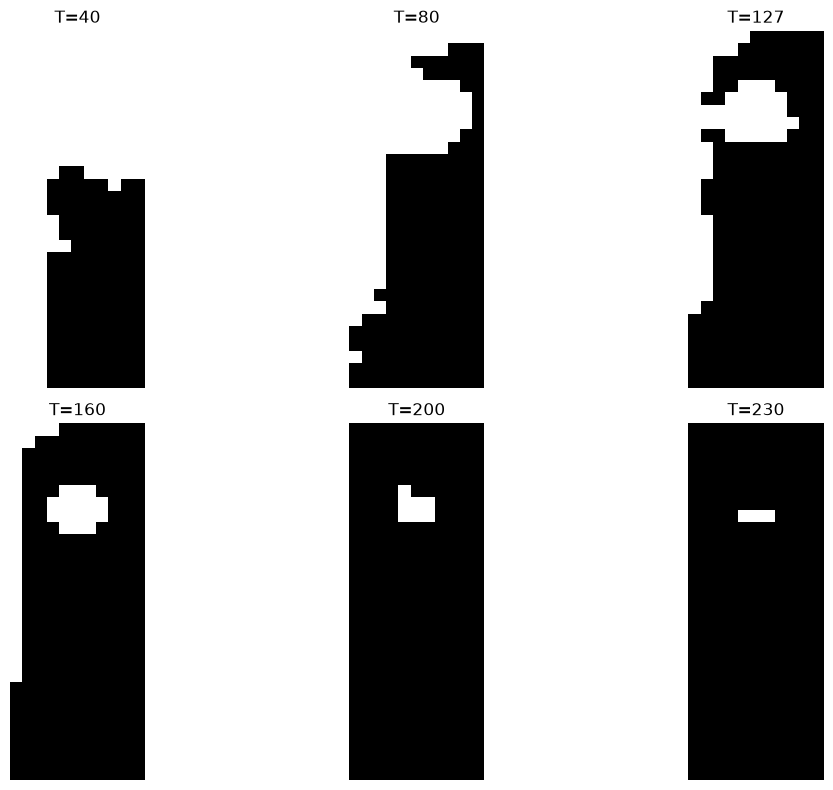

In [30]:
thresholds = [40, 80, 127, 160, 200, 230]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, t in zip(axes.ravel(), thresholds):
    _, m = cv.threshold(value_Stoplight, t, 255, cv.THRESH_BINARY)
    
    ax.imshow(m, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"T={t}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [31]:
# Метод Оцу

Порог Оцу: 97.0


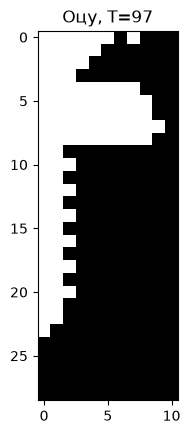

In [32]:
otsu_t, otsu = cv.threshold(value_Stoplight, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print("Порог Оцу:", otsu_t)

plt.imshow(otsu, cmap="gray", vmin=0, vmax=255)
plt.title(f"Оцу, T={otsu_t:.0f}")
plt.show()

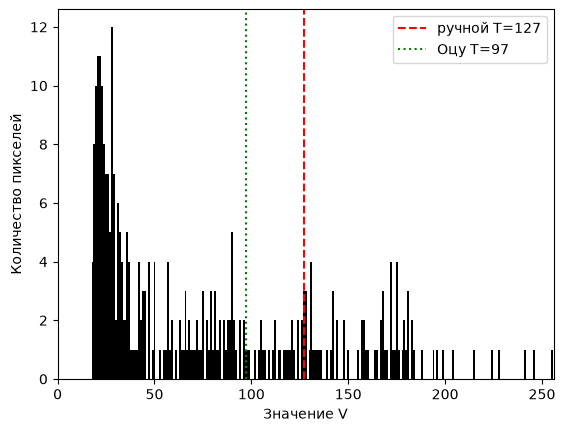

In [33]:
hist, _ = np.histogram(value_Stoplight, bins=256, range=(0, 256))
plt.bar(np.arange(256), hist, width=1, color="black")
plt.axvline(127, color="red",    linestyle="--", label="ручной T=127")
plt.axvline(otsu_t, color="green", linestyle=":",  label=f"Оцу T={otsu_t:.0f}")
plt.xlim(0, 256)
plt.xlabel("Значение V")
plt.ylabel("Количество пикселей")
plt.legend()
plt.show()